# 2. Windows and features

Non-overlapping 1s/2s windows contain 50/100 readings. Boundaries respect subjects, invalid readings and timestamp gaps. Incomplete tails are discarded. Majority voting assigns labels; mixed windows are retained.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in [Path.cwd(), Path.cwd() / 'harth_project', Path.cwd().parent]
             if (p / 'har_utils.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Project root not found.')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from har_utils import *


## Feature datasets

Each window has 58 time-domain features. The 24 cached frequency features are excluded from model inputs.


In [2]:
subject_files()
record_environment()
datasets = {}
preparation_rows = []
for duration in (1, 2):
    X_duration, meta_duration = build_windows(seconds=duration)
    datasets[duration] = (X_duration, meta_duration)
    audit = pd.read_csv(ROOT / 'results' / f'window_audit_{duration}s.csv')
    preparation_rows.append({
        'window_seconds': duration,
        'samples_per_window': duration * 50,
        'windows': len(meta_duration),
        'subjects': meta_duration.subject.nunique(),
        'time_features': len(feature_columns(X_duration)),
        'mixed_fraction': (meta_duration.purity < 1).mean(),
        'mean_purity': meta_duration.purity.mean(),
        'used_samples': audit.used_samples.sum(),
        'discarded_samples': audit.discarded_samples.sum(),
    })
    print(f'{duration}s: saved {len(meta_duration):,} windows, {X_duration.shape[1]} cached features')
    display(audit)

preparation_summary = pd.DataFrame(preparation_rows)
preparation_summary.to_csv(ROOT / 'results/window_preparation_summary.csv', index=False)
display(preparation_summary)

X, meta = datasets[2]
display(X.head()); display(meta.head())


1s: saved 120,765 windows, 82 cached features


,subject,input_samples,used_samples,discarded_samples
0,S006,408709,0,408709
1,S008,418989,418150,839
2,S009,154464,154250,214
3,S010,351649,351400,249
4,S012,382414,381650,764
5,S013,369077,367750,1327
6,S014,366487,364700,1787
7,S015,418392,417350,1042
8,S016,355418,354650,768
9,S017,366609,365750,859


2s: saved 60,214 windows, 82 cached features


,subject,input_samples,used_samples,discarded_samples
0,S006,408709,0,408709
1,S008,418989,417200,1789
2,S009,154464,154000,464
3,S010,351649,351000,649
4,S012,382414,380700,1714
5,S013,369077,366400,2677
6,S014,366487,362800,3687
7,S015,418392,416300,2092
8,S016,355418,353600,1818
9,S017,366609,364700,1909


,window_seconds,samples_per_window,windows,subjects,time_features,mixed_fraction,mean_purity,used_samples,discarded_samples
0,1,50,120765,21,58,0.045270,0.987716,6038250,423078
1,2,100,60214,21,58,0.080612,0.977210,6021400,439928


,back_x__mean,back_y__mean,back_z__mean,thigh_x__mean,thigh_y__mean,thigh_z__mean,back_mag__mean,thigh_mag__mean,back_x__std,back_y__std,...,back_mag__centroid_hz,thigh_mag__centroid_hz,back_x__spectral_entropy,back_y__spectral_entropy,back_z__spectral_entropy,thigh_x__spectral_entropy,thigh_y__spectral_entropy,thigh_z__spectral_entropy,back_mag__spectral_entropy,thigh_mag__spectral_entropy
0,-1.009671,0.064953,-0.017607,-0.933570,0.089740,-0.290792,1.035176,1.022558,0.318741,0.073789,...,9.653871,13.374265,4.299585,5.171286,5.166261,5.359716,4.626783,4.920246,4.826366,5.215875
1,-1.007402,0.067252,-0.011460,-0.924730,0.127452,-0.363319,1.009792,1.001855,0.006876,0.007649,...,9.035035,16.741358,4.938225,3.511930,3.276525,4.252595,4.313212,3.728993,4.963929,4.259290
2,-1.008901,0.059910,-0.019103,-0.918908,0.129832,-0.375349,1.010957,1.001301,0.007098,0.009741,...,9.807743,15.141164,4.823479,3.878168,3.991421,4.708186,3.938572,3.714400,4.836551,4.604870
3,-1.007072,0.063865,-0.005934,-0.924645,0.120150,-0.364419,1.009222,1.001266,0.006919,0.009482,...,9.192620,13.388407,4.811028,4.341228,3.444903,4.766727,4.073306,4.106541,4.796508,4.952672
4,-1.010306,0.053685,-0.074572,-0.937621,0.097055,-0.333495,1.014758,1.001264,0.008053,0.011716,...,7.992278,10.137164,4.615922,4.051141,3.722805,3.713804,3.961575,1.982973,4.539727,4.905351


,subject,start_row,start_time,label,purity
0,S008,0,2019-01-12 00:00:00,6,1.0
1,S008,100,2019-01-12 00:00:02,6,1.0
2,S008,200,2019-01-12 00:00:04,6,1.0
3,S008,300,2019-01-12 00:00:06,6,1.0
4,S008,400,2019-01-12 00:00:08,6,1.0


## Window boundaries

Consecutive 2s windows, per-reading activities and majority-label purity.


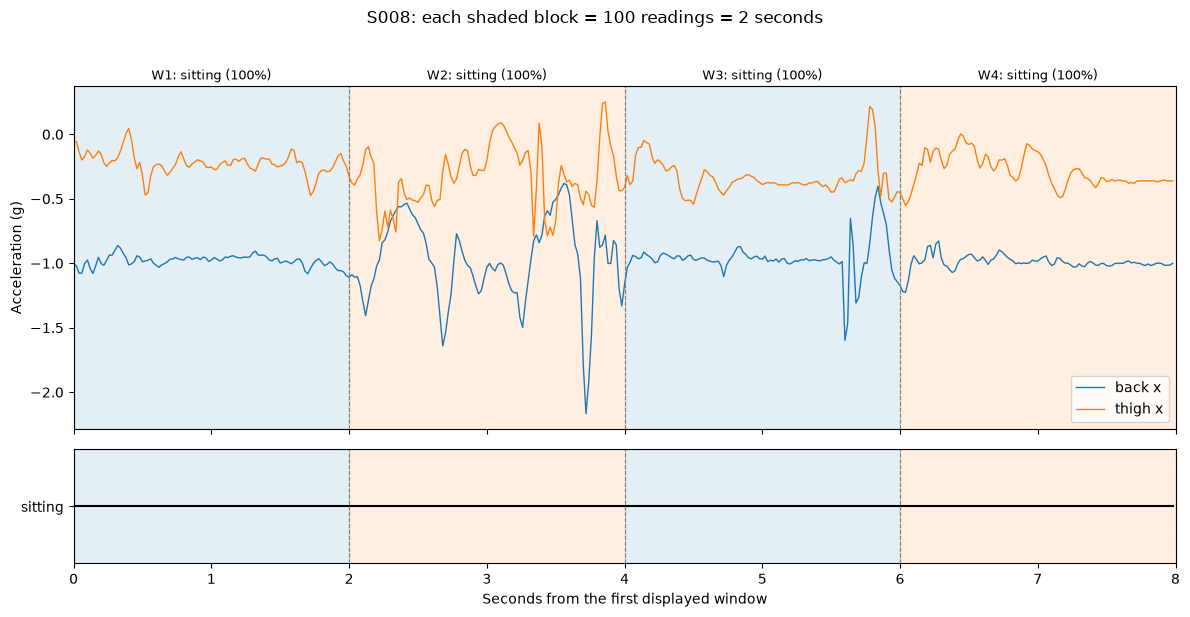

,subject,start_row,label,purity,end_row_exclusive,activity
2793,S008,280974,7,1.0,281074,sitting
2794,S008,281074,7,1.0,281174,sitting
2795,S008,281174,7,1.0,281274,sitting
2796,S008,281274,7,1.0,281374,sitting


In [3]:
subject = meta.subject.iloc[0]
subject_windows = meta[meta.subject == subject].sort_values('start_row').copy()
row_break = subject_windows.start_row.diff().ne(100)
time_break = pd.to_datetime(subject_windows.start_time).diff().dt.total_seconds().sub(2).abs().gt(.001)
blocks = (row_break | time_break).cumsum()
longest_block = blocks.value_counts().idxmax()
shown = subject_windows[blocks == longest_block].head(4)
frame = read_subject(ROOT / 'data/harth' / f'{subject}.csv')
left = int(shown.start_row.iloc[0])
right = int(shown.start_row.iloc[-1]) + 100
segment = frame.iloc[left:right]
seconds = np.arange(len(segment)) / 50

active_labels = [label for label in LABELS if label in segment.label.unique()]
label_positions = {label: i for i, label in enumerate(active_labels)}
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})
axes[0].plot(seconds, segment.back_x, label='back x', linewidth=1)
axes[0].plot(seconds, segment.thigh_x, label='thigh x', linewidth=1)
axes[0].set_ylabel('Acceleration (g)')
axes[0].legend(loc='lower right')
axes[1].step(seconds, segment.label.map(label_positions), where='post', color='black')
axes[1].set_yticks(range(len(active_labels)), [ACTIVITIES[label] for label in active_labels])
axes[1].set_ylim(-.5, len(active_labels) - .5)

for number, row in enumerate(shown.itertuples(), start=1):
    begin = (row.start_row - left) / 50
    end = begin + 2
    color = 'tab:blue' if number % 2 else 'tab:orange'
    for ax in axes:
        ax.axvspan(begin, end, color=color, alpha=.12)
        ax.axvline(begin, color='grey', linestyle='--', linewidth=.8)
    axes[0].text((begin + end) / 2, 1.02,
        f'W{number}: {ACTIVITIES[row.label]} ({row.purity:.0%})',
        transform=axes[0].get_xaxis_transform(), ha='center', fontsize=9)
axes[-1].axvline(end, color='grey', linestyle='--', linewidth=.8)
axes[-1].set_xlim(0, end)
axes[-1].set_xlabel('Seconds from the first displayed window')
fig.suptitle(f'{subject}: each shaded block = 100 readings = 2 seconds', y=1.02)
plt.tight_layout(); plt.show()

display(shown[['subject', 'start_row', 'label', 'purity']].assign(
    end_row_exclusive=shown.start_row + 100,
    activity=shown.label.map(ACTIVITIES)))


## Mixed-window labels

Activity counts determine the majority label.


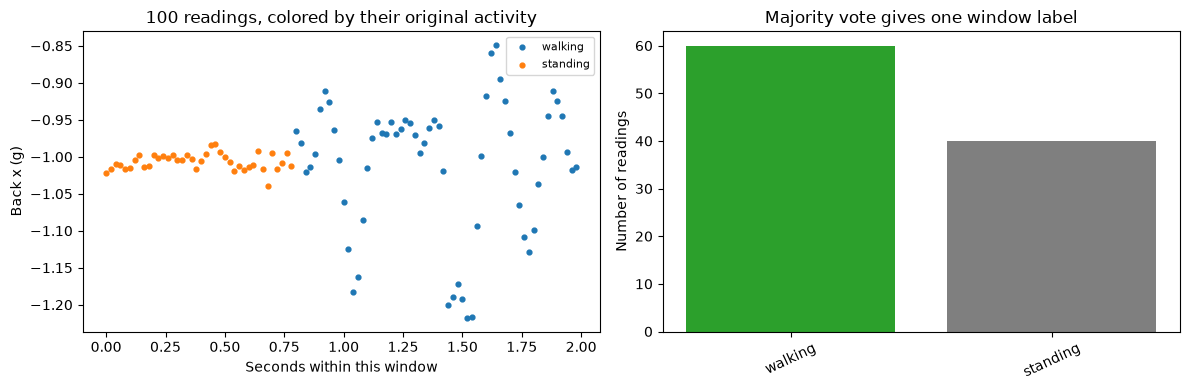

Saved label: walking
Purity: 0.6 | winning votes / 100: 0.6


In [4]:
mixed = meta[meta.purity < 1]
example_window = mixed.iloc[0] if len(mixed) else meta.iloc[0]
example_frame = read_subject(ROOT / 'data/harth' / f'{example_window.subject}.csv')
start = int(example_window.start_row)
readings = example_frame.iloc[start:start+100]
votes = readings.label.value_counts()
winning_label = int(example_window.label)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t = np.arange(100) / 50
for label in LABELS:
    mask = readings.label.to_numpy() == label
    if mask.any():
        axes[0].scatter(t[mask], readings.back_x.to_numpy()[mask],
                        s=12, label=ACTIVITIES[label])
axes[0].set(xlabel='Seconds within this window', ylabel='Back x (g)',
            title='100 readings, colored by their original activity')
axes[0].legend(fontsize=8)
axes[1].bar([ACTIVITIES[label] for label in votes.index], votes.to_numpy(),
            color=['tab:green' if label == winning_label else 'tab:grey'
                   for label in votes.index])
axes[1].set(ylabel='Number of readings', title='Majority vote gives one window label')
axes[1].tick_params(axis='x', labelrotation=25)
plt.tight_layout(); plt.show()
print('Saved label:', ACTIVITIES[winning_label])
print('Purity:', example_window.purity, '| winning votes / 100:', votes[winning_label] / 100)


## Feature calculation

Magnitude = √(x²+y²+z²), RMS = √mean(signal²), SMA = mean(|x|+|y|+|z|). Seven statistics on eight channels plus two SMA values give 58 features.


In [5]:
first = meta.iloc[0]
frame = read_subject(ROOT / 'data/harth' / (first.subject + '.csv'))
start = int(first.start_row)
window = frame.iloc[start:start+100][AXES].to_numpy()
print('Back x mean:', window[:, 0].mean())
print('Back x RMS:', np.sqrt(np.mean(window[:, 0] ** 2)))
print('Back mean magnitude:', np.linalg.norm(window[:, :3], axis=1).mean())
print('Back SMA:', np.abs(window[:, :3]).sum(axis=1).mean())
print('Stored mean:', X.iloc[0]['back_x__mean'])


Back x mean: -1.0096709833058402
Back x RMS: 1.0587877782475783
Back mean magnitude: 1.0351761833041153
Back SMA: 1.1341799067860954
Stored mean: -1.0096709833058404


## Signal statistics

A 2s window and its mean, standard deviation, extrema and RMS.


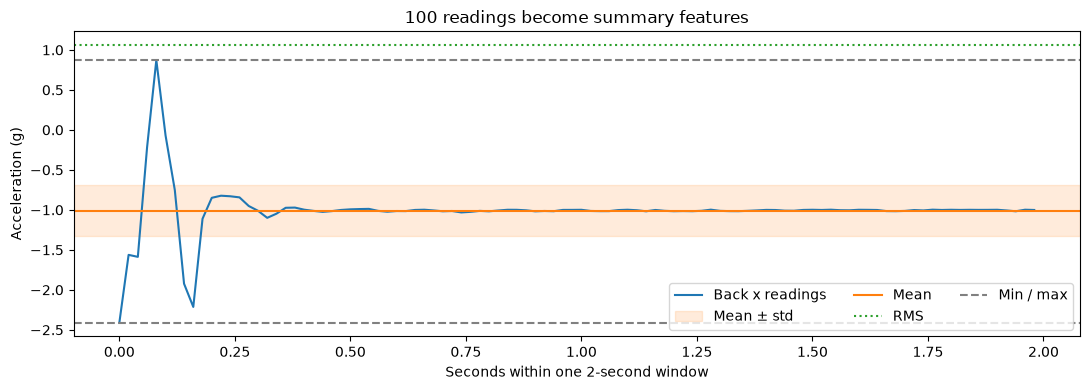

,back_x__mean,back_x__std,back_x__min,back_x__max,back_x__median,back_x__range,back_x__rms
0,-1.009671,0.318741,-2.409951,0.873471,-1.005548,3.283422,1.058788


In [6]:
signal = window[:, 0]
time_in_window = np.arange(len(signal)) / 50
mean = signal.mean()
std = signal.std()
rms = np.sqrt(np.mean(signal ** 2))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(time_in_window, signal, label='Back x readings')
ax.axhspan(mean - std, mean + std, alpha=.15, color='tab:orange', label='Mean ± std')
ax.axhline(mean, color='tab:orange', label='Mean')
ax.axhline(rms, color='tab:green', linestyle=':', label='RMS')
ax.axhline(signal.min(), color='grey', linestyle='--', label='Min / max')
ax.axhline(signal.max(), color='grey', linestyle='--')
ax.set(xlabel='Seconds within one 2-second window', ylabel='Acceleration (g)',
       title='100 readings become summary features')
ax.legend(ncol=3); plt.tight_layout(); plt.show()
columns = [f'back_x__{stat}' for stat in ['mean', 'std', 'min', 'max', 'median', 'range', 'rms']]
display(X.loc[[0], columns])


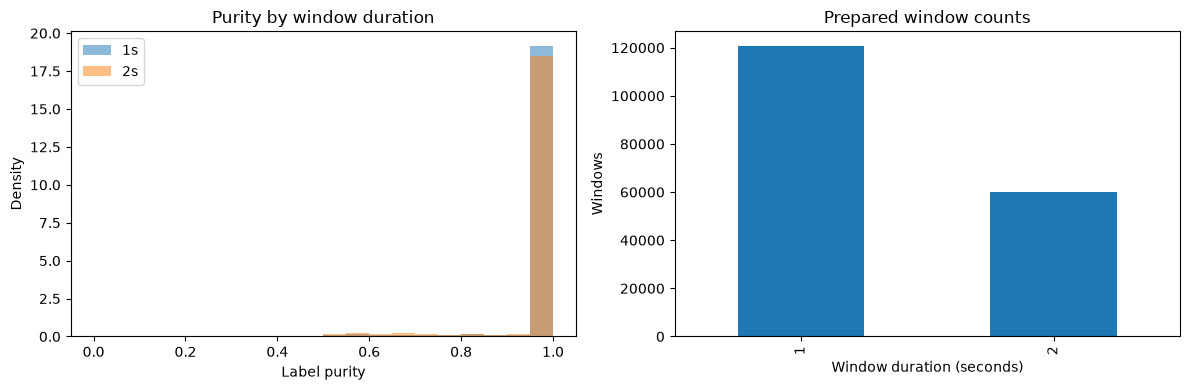

,window_seconds,samples_per_window,windows,subjects,time_features,mixed_fraction,mean_purity,used_samples,discarded_samples
0,1,50,120765,21,58,0.045270,0.987716,6038250,423078
1,2,100,60214,21,58,0.080612,0.977210,6021400,439928


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for duration, (_, window_meta) in datasets.items():
    axes[0].hist(window_meta.purity, bins=np.linspace(0, 1, 21),
                 alpha=.5, density=True, label=f'{duration}s')
preparation_summary.set_index('window_seconds')['windows'].plot.bar(ax=axes[1])
axes[0].set(xlabel='Label purity', ylabel='Density', title='Purity by window duration')
axes[0].legend()
axes[1].set(xlabel='Window duration (seconds)', ylabel='Windows', title='Prepared window counts')
plt.tight_layout(); plt.show()
display(preparation_summary)


## Prepared data

Feature tables, metadata and subject audits are stored separately for each duration. Scaling occurs within training folds.
